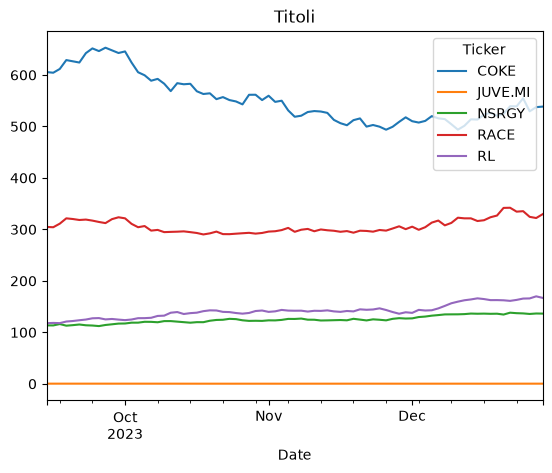

In [1]:
import yfinance as yf
import pandas as pd #salvare quello che abbiamo caricato in un file excel
import matplotlib.pyplot as plt
import numpy as np
import statistics
GayLussac = ["COKE", "NSRGY", "RACE", "RL","JUVE.MI"] #aziende in borsa
data_inizio = "2023-09-14" #Abbiamo Scelto una data di inizio
data_fine = "2023-12-31" #Abbiamo scelto una data di fine


GayLussac_data = pd.read_excel("dati.xlsx", header=[0, 1], index_col=0) # Carica la serie storica del portafoglio titoli
GayLussac_data.Close.plot(title="Titoli")
plt.show()

In [2]:
from datetime import datetime, timedelta

# Lista delle 5 azioni di tuo interesse
azioni = ["COKE", "NSRGY", "RACE", "RL","JUVE.MI"]

# Definisci l'arco di tempo desiderato (in giorni)
arco_tempo = 420

# Ottieni la data odierna e la data arco_tempo giorni fa
data_fine = datetime.today().strftime('%Y-%m-%d')
data_inizio = (datetime.today() - timedelta(days=arco_tempo)).strftime('%Y-%m-%d')

# Cicla attraverso le azioni e calcola il valore massimo
for azione in azioni:
    df = yf.download(azione, start=data_inizio, end=data_fine)
    max_value = df['Close'].squeeze().max()
    print(f"Valore massimo dell'arco di tempo di {arco_tempo} giorni per {azione}: {max_value}")

[*********************100%***********************]  1 of 1 completed


Valore massimo dell'arco di tempo di 420 giorni per COKE: 216.07342529296875


[*********************100%***********************]  1 of 1 completed


Valore massimo dell'arco di tempo di 420 giorni per NSRGY: 106.55000305175781


[*********************100%***********************]  1 of 1 completed


Valore massimo dell'arco di tempo di 420 giorni per RACE: 498.338623046875


[*********************100%***********************]  1 of 1 completed


Valore massimo dell'arco di tempo di 420 giorni per RL: 412.0654296875


[*********************100%***********************]  1 of 1 completed

Valore massimo dell'arco di tempo di 420 giorni per JUVE.MI: 3.01200008392334


In [3]:
# Funzione per ottenere il prezzo di chiusura per una data azione
def get_close_price(ticker_symbol):
    data = yf.download(ticker_symbol, period="420d")
    return data['Close'].squeeze().iloc[-1]

# Lista delle 5 azioni scelte
stocks = ["COKE", "NSRGY", "RACE", "RL","JUVE.MI"]

# Dizionario per memorizzare i prezzi di chiusura delle azioni
close_prices = {}

# Ottenere i prezzi di chiusura di tutte le azioni
for stock in stocks:
    close_prices[stock] = get_close_price(stock)

# Trovare l'azione con il prezzo di chiusura più alto
max_close_price = max(close_prices, key=close_prices.get)

print("L'azione con il prezzo di chiusura più alto è:", max_close_price)
print("Prezzo di chiusura più alto:", close_prices[max_close_price])

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

L'azione con il prezzo di chiusura più alto è: COKE
Prezzo di chiusura più alto: nan


In [4]:
azioni = ["COKE", "NSRGY", "RACE", "RL","JUVE.MI"]
prezzi = {
    "COKE": 60.5,
    "NSRGY": 2.22,
    "RACE": 7.65,
    "RL": 55.25,
    "JUVE.MI": 0.21
}
variazioni = {
    "COKE": 0.02,
    "NSRGY": -0.03,
    "RACE": -0.10,
    "RL": -0.15,
    "JUVE.MI": -0.05
}
df = pd.DataFrame({"Azioni": azioni, "Prezzo": list(prezzi.values()), "Variazione": list(variazioni.values())}, index=list(prezzi.keys()))

df["Variazione %"] = df["Variazione"] * 100

portafoglio = sum(list(prezzi.values()))

variazione_totale = sum(list(variazioni.values()))

variazione_percentuale = variazione_totale / portafoglio * 100

print("Valore portafoglio:", portafoglio)
print("Variazione percentuale:", variazione_percentuale)
print(df.to_string())

Valore portafoglio: 125.83
Variazione percentuale: -0.2463641420964794
          Azioni  Prezzo  Variazione  Variazione %
COKE        COKE   60.50        0.02           2.0
NSRGY      NSRGY    2.22       -0.03          -3.0
RACE        RACE    7.65       -0.10         -10.0
RL            RL   55.25       -0.15         -15.0
JUVE.MI  JUVE.MI    0.21       -0.05          -5.0


Inserire il proprio budget:  1200


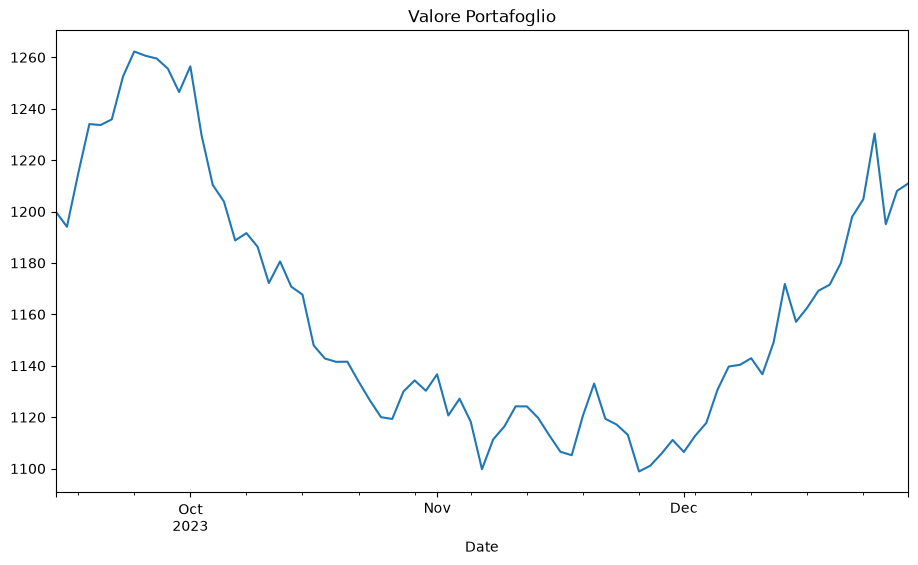

In [7]:

Budget= float(input("Inserire il proprio budget: "))
allocazione=[0.5, 0.2, 0.1, 0.1, 0.1]
Quantità= []
for i in range(5):
    Quantità.append(Budget*allocazione[i]/GayLussac_data.Close.iloc[0,i])#accede come una matrice 0=riga e i=ogni azione
portafoglio =  (GayLussac_data.Close * Quantità).sum(axis= 1)

portafoglio.plot(figsize=(11,6), title="Valore Portafoglio")
plt.title("Valore Portafoglio")
plt.show()

portafoglio.to_excel('portafoglio.xlsx') # salva il valore del portafoglio (non sovrascrive dati.xlsx)

In [8]:
moda=statistics.mode(portafoglio)
print("Moda: ",moda)
media = statistics.mean(portafoglio)
print("Media: ",media)
devstd = statistics.stdev(portafoglio)
print("Deviazione Standard: ",devstd)

Moda:  1200.0
Media:  1161.7436931727295
Deviazione Standard:  48.489542357089526
